# Parte 2 – Mapas del Perú

In [32]:
# Ejecutar en caso no se tenga instalado
# %pip install geopandas folium mapclassify


In [33]:
import unicodedata

import pandas as pd
import geopandas as gpd
import folium

#### Paso 1: Verificar el ubigeo (texto de 2 dígitos) o el nombre del departamento en el dataset

In [34]:
datos = pd.read_csv("datos/tabla_final_2022_2025.csv", dtype={"ubigeo": str})
print(datos.shape)
datos.head()

(100, 10)


,temporada,ubigeo,departamento,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,2022,01,Amazonas,Chachapoyas,-6.23169,-77.86903,436.5,1,1,0
1,2022,02,Áncash,Huaraz,-9.52614,-77.52869,975.3,7,0,0
2,2022,03,Apurímac,Abancay,-13.63426,-72.88380,711.8,2,0,0
3,2022,04,Arequipa,Arequipa,-16.39899,-71.53747,189.9,0,0,0
4,2022,05,Ayacucho,Ayacucho,-13.16380,-74.22345,485.1,0,1,0


In [35]:
print("Tipo de ubigeo:", datos["ubigeo"].dtype, "| ejemplo:", datos["ubigeo"].iloc[0])
print("Todos tienen 2 dígitos:", datos["ubigeo"].str.len().eq(2).all())
print("Departamentos distintos:", datos["departamento"].nunique())
print("Un ubigeo por departamento:",
      datos.groupby("ubigeo")["departamento"].nunique().eq(1).all())

Tipo de ubigeo: str | ejemplo: 01
Todos tienen 2 dígitos: True
Departamentos distintos: 25
Un ubigeo por departamento: True


La tabla tiene una fila por departamento y temporada (25 × 4). Para el mapa necesitamos **una fila por departamento**, así que resumimos las 4 temporadas: lluvia promedio por temporada y total de declaratorias de emergencia.

In [36]:
depto = (datos.groupby(["ubigeo", "departamento"], as_index=False)
              .agg(lluvia_promedio_mm=("lluvia_total_mm", "mean"),
                   dias_lluvia_fuerte=("dias_lluvia_fuerte", "sum"),
                   declaratorias=("declaratorias", "sum"),
                   prorrogas=("prorrogas", "sum")))
depto["lluvia_promedio_mm"] = depto["lluvia_promedio_mm"].round(1)
print(depto.shape)
depto.head()

(25, 6)


,ubigeo,departamento,lluvia_promedio_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,01,Amazonas,433.5,4,16,7
1,02,Áncash,1148.8,30,19,12
2,03,Apurímac,732.2,10,15,6
3,04,Arequipa,306.6,5,19,8
4,05,Ayacucho,488.0,4,21,10


#### Paso 2: Cargar el GeoJSON o Shapefile departamental y unirlo con los datos

El GeoJSON solo trae el nombre del departamento (en mayúsculas y sin tildes),no trae ubigeo. Por eso le agregamos el ubigeo de 2 dígitos usando el nombre normalizado (sin tildes y en mayúsculas), y después cruzamos por ubigeo como texto.

In [37]:
mapa_base = gpd.read_file("datos/departamentos_peru.geojson")
print(mapa_base.shape, mapa_base.crs)
mapa_base.head()

(25, 2) EPSG:4326


,departamento,geometry
0,AMAZONAS,"POLYGON ((-78.03025 -6.7661, -78.04983 -6.6838..."
1,ANCASH,"POLYGON ((-77.69239 -10.3209, -77.75251 -10.32..."
2,APURIMAC,"POLYGON ((-73.51174 -14.53852, -73.52075 -14.5..."
3,AREQUIPA,"POLYGON ((-72.72968 -16.64631, -72.77421 -16.6..."
4,AYACUCHO,"POLYGON ((-74.50188 -15.16058, -74.51267 -15.1..."


In [38]:
def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return texto.upper().strip()

codigos = dict(zip(depto["departamento"].map(normalizar), depto["ubigeo"]))
mapa_base["ubigeo"] = mapa_base["departamento"].map(normalizar).map(codigos)
mapa_base[["departamento", "ubigeo"]].head()

,departamento,ubigeo
0,AMAZONAS,01
1,ANCASH,02
2,APURIMAC,03
3,AREQUIPA,04
4,AYACUCHO,05


Se realiza el merge y el reporte de no cruces

In [39]:
mapa = mapa_base.merge(depto, on="ubigeo", how="outer",
                       suffixes=("", "_tabla"), indicator=True)
print(mapa["_merge"].value_counts())

no_cruzaron = mapa.loc[mapa["_merge"] != "both"]
nombres = no_cruzaron["departamento"].fillna(no_cruzaron["departamento_tabla"]).tolist()
print("Departamentos que no cruzaron:", nombres or "ninguno")

_merge
both          25
left_only      0
right_only     0
Name: count, dtype: int64
Departamentos que no cruzaron: ninguno


In [40]:
mapa = mapa.drop(columns=["_merge", "departamento_tabla"])

mapa.head()

,departamento,geometry,ubigeo,lluvia_promedio_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,AMAZONAS,"POLYGON ((-78.03025 -6.7661, -78.04983 -6.6838...",01,433.5,4,16,7
1,ANCASH,"POLYGON ((-77.69239 -10.3209, -77.75251 -10.32...",02,1148.8,30,19,12
2,APURIMAC,"POLYGON ((-73.51174 -14.53852, -73.52075 -14.5...",03,732.2,10,15,6
3,AREQUIPA,"POLYGON ((-72.72968 -16.64631, -72.77421 -16.6...",04,306.6,5,19,8
4,AYACUCHO,"POLYGON ((-74.50188 -15.16058, -74.51267 -15.1...",05,488.0,4,21,10


In [41]:
print("Polígonos sin datos después del cruce:", mapa["declaratorias"].isna().sum())
print("Total de declaratorias en el mapa:", int(mapa["declaratorias"].sum()))
print("Total de declaratorias en la tabla:", int(datos["declaratorias"].sum()))

Polígonos sin datos después del cruce: 0
Total de declaratorias en el mapa: 331
Total de declaratorias en la tabla: 331


Los dos totales coinciden: el cruce no perdió ningún departamento.

#### Paso 3. Hacer un mapa estático con Geopandas

Hacemos dos coropletas por cuantiles: con `scheme="quantiles"` cada color agrupa la misma cantidad de departamentos, así un valor extremo no deja al resto en blanco.

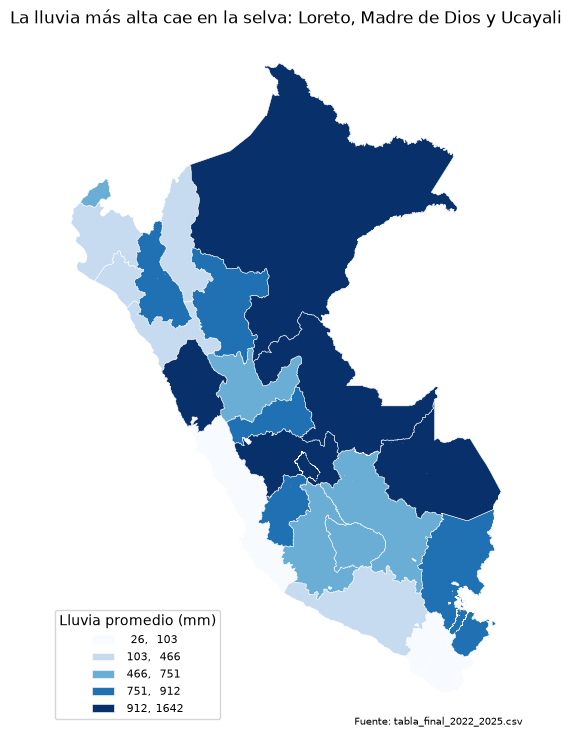

In [42]:
ax = mapa.plot(column="lluvia_promedio_mm", cmap="Blues", figsize=(7, 9),
               scheme="quantiles", k=5, legend=True,
               edgecolor="white", linewidth=0.4,
               legend_kwds={"loc": "lower left", "fontsize": 8,
                            "title": "Lluvia promedio (mm)", "fmt": "{:.0f}"})
ax.set_title("La lluvia más alta cae en la selva: Loreto, Madre de Dios y Ucayali")
ax.set_axis_off()
ax.annotate("Fuente: tabla_final_2022_2025.csv",
            xy=(1, 0), xycoords="axes fraction", ha="right", fontsize=7);

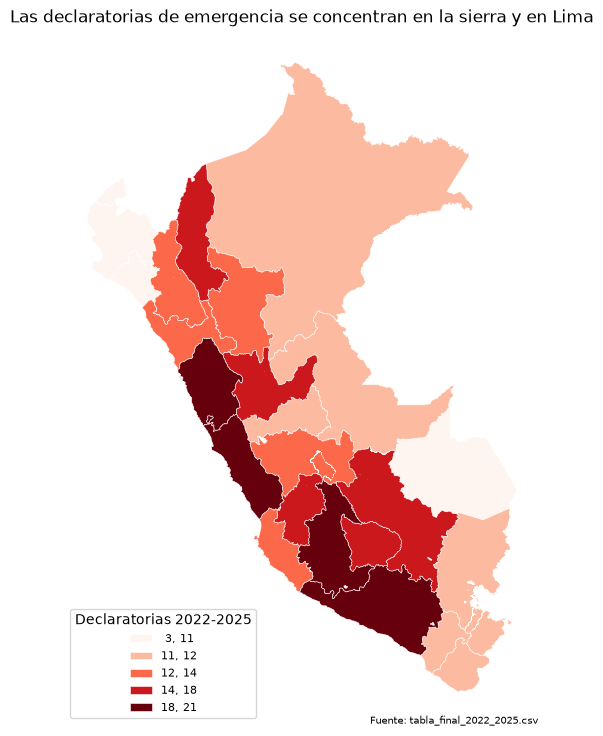

In [43]:
ax = mapa.plot(column="declaratorias", cmap="Reds", figsize=(7, 9),
               scheme="quantiles", k=5, legend=True,
               edgecolor="white", linewidth=0.4,
               legend_kwds={"loc": "lower left", "fontsize": 8,
                            "title": "Declaratorias 2022-2025", "fmt": "{:.0f}"})
ax.set_title("Las declaratorias de emergencia se concentran en la sierra y en Lima")
ax.set_axis_off()
ax.annotate("Fuente: tabla_final_2022_2025.csv",
            xy=(1, 0), xycoords="axes fraction", ha="right", fontsize=7);

#### Paso 4: Hacer un mapa interactivo con Folium con tooltip

`Choropleth` pinta los departamentos y la capa `GeoJson` encima muestra el dato al pasar el mouse. **Antes del commit, borrar la salida de esta celda** para no guardar el mapa dentro del notebook.

In [ ]:
m = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles="OpenStreetMap")

folium.Choropleth(
    geo_data=mapa, data=mapa,
    columns=["ubigeo", "declaratorias"],
    key_on="feature.properties.ubigeo",
    fill_color="Reds", fill_opacity=0.7, line_opacity=0.3,
    legend_name="Declaratorias de emergencia 2022-2025 (ene-may en cada año)",
    bins=list(mapa["declaratorias"].quantile([0, 0.2, 0.4, 0.6, 0.8, 1])),
).add_to(m)

folium.GeoJson(
    mapa,
    style_function=lambda x: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(
        fields=["departamento", "declaratorias", "prorrogas", "lluvia_promedio_mm"],
        aliases=["Departamento:", "Declaratorias:", "Prórrogas:", "Lluvia promedio (mm):"],
    ),
).add_to(m)

m

#### Paso 5: Comentar en una celda de texto qué patrón geográfico resalta en el mapa

- **La lluvia y las declaratorias de emergencias no están en el mismo lugar.** La lluvia más alta está en la selva (Loreto, Madre de Dios, Ucayali), pero las declaratorias de emergencia se concentran en la sierra centro y sur (Ayacucho, Cusco, Huánuco, Huancavelica, Áncash) y en la costa sur y centro (Lima, Arequipa).
- **Lima es el caso más claro:** casi no llueve (≈42 mm por temporada) y aun así tiene 20 declaratorias, el segundo valor más alto. En cambio, Madre de Dios, con más de 1,200 mm, tuvo solo 6.
- **El norte costero** (Tumbes, Lambayeque, Piura) y Callao quedan en los tonos más claros de declaratorias.